In [1]:
from uspas_llrf import LLRFApp
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import signal
from uspas_llrf.utils import calc_ps, plot_ps, plot_raw_bufs_df, plot_iq_wfms_df
import time
from pprint import pprint


plt.rcParams['figure.figsize'] = [6, 4]
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.grid.which'] = "both"
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['font.size'] = 8

plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

%load_ext autoreload
%autoreload 2

# Marble and LLRF info

In [2]:

slac_b15_ip = '192.168.19.171:803'
llrf = LLRFApp(addr=slac_b15_ip,
               conf='LEMP',
               chan_keep=0x3ff)
llrf.get_bsp_info()

Marble Variant: V1.4
ADN4600 U2:
  IN 2 -> OUT 0
  IN 3 -> OUT 1
  IN 2 -> OUT 2
  IN 3 -> OUT 3
INA219 U57, 12V:
  Vshunt     :      0.1 mV
  Power      :     48.7 mW
  Vbus       :     11.9 V
  Current    :   -959.9 mA
INA219 U17, FMC1:
  Vshunt     :    -31.4 mV
  Power      :      3.9 mW
  Vbus       :     11.9 V
  Current    :    200.5 mA
INA219 U32, FMC2:
  Vshunt     :    -20.5 mV
  Power      :      0.0 mW
  Vbus       :     11.9 V
  Current    :    137.7 mA
 PCA9555 U34, QSFP:
  I0         :    01111111
  I1         :    01001111
 PCA9555 U39, MISC:
  I0         :    11111110
  I1         :    11110011
QSFP 2 is present:
  Vendor     :    FS              
  Part       :    QSFP-SR4-40G    
  Serial     :    C2308346198     
  TXRX_LOS   :    11111101
  Temp       :    37 C
  Volt       :    3305 mV
  TxBias0    :    0 uA
  TxPwr0     :    0 uW
  RxPwr0     :    0 uW
  TxBias1    :    0 uA
  TxPwr1     :    0 uW
  RxPwr1     :    210 uW
  TxBias2    :    0 uA
  TxPwr2     :    

In [3]:
git_id = hex(llrf.reg_read([('git_rev_id')])[0])
print(f"git_id: {git_id}")
assert llrf.wfm_len == 1024, "Waveform length is not 1024 (value for LEMP)"
assert len(llrf.reg_read([('iq_buf')])[0]) == 32768, "IQ buffer length is not 32768 (2^15)"


git_id: 0x4efd8574


In [4]:
mo_adc_chan = llrf.read_reg('prl_adc_chan')
mo_adc = f'adc{mo_adc_chan}'
fdbk_adc = 'adc0'
print(f'MO ADC = {mo_adc}, FDBK ADC = {fdbk_adc}')

MO ADC = adc3, FDBK ADC = adc0


In [5]:
pprint(llrf.model.cal_factors)
tx_gain = llrf.model.cal_factors.tx_gain

LLRFCalibrations(rx_gain=np.float64(3.1140127017135355),
                 tx_gain=np.float64(1.548405151243775),
                 rx_phase_off_deg=np.float64(2.3163705674031023),
                 tx_phase_off_deg=np.float64(115.71428571428538),
                 rx_dds_omega_deg=np.float64(77.14285714285714),
                 tx_dds_omega_deg=np.float64(141.42857142857142),
                 cic_wfm_gain=np.complex128(11.58233428572094-3.4000580129145394e-16j),
                 inlk_gain=np.complex128(0.596041493687356-1.7497126284290302e-17j),
                 inlk_tx_gain=np.complex128(-7.223112788297967e-16-0.33522180652057704j),
                 rx_iq_gain=np.complex128(1.8909933527707667-5.551115123125782e-17j),
                 tx_iq_gain=np.complex128(-2.0260322971788112e-15+0.9402735726757956j),
                 max_adc_input=31129.6,
                 max_dac_drive=31129.6,
                 max_amp_setpoint=np.float64(20104.298913623978))


In [6]:
llrf.model.tx

< TX          :   Amp gain= 1.548,   Phs gain=   90.00 deg >
DDS           :   Amp gain= 0.940,   Phs gain=  115.71 deg;
DUC           :   Amp gain= 1.000,   Phs gain= -115.71 deg;
CORDIC        :   Amp gain= 1.647,   Phs gain=   90.00 deg;

In [7]:
# Include rx_cordic in dsp_core.v
llrf.model.rx

< RX          :   Amp gain= 3.114,   Phs gain=   -0.00 deg >
WashoutFilter :   Amp gain= 1.031,   Phs gain=  -74.83 deg;
DDS           :   Amp gain= 0.940,   Phs gain=   -2.32 deg;
DDC           :   Amp gain= 1.950,   Phs gain=   77.14 deg;
CORDIC        :   Amp gain= 1.647,   Phs gain=    0.00 deg;

In [8]:
llrf.model.rx_iq_gain

np.complex128(1.8909933527707667-5.551115123125782e-17j)

In [9]:
llrf.model.cic_mon

< CICWaveRecorder:   Amp gain= 6.125,   Phs gain=    0.00 deg >

In [10]:
llrf.model.cic_wfm_gain

np.complex128(11.58233428572094-3.4000580129145394e-16j)

In [11]:
llrf.init_cw_demo()
llrf.init_loop('loop0', amp_setp_adc=2e4)
llrf.init_loop('loop1', amp_setp_adc=3e4)

In [12]:
print(llrf.read_reg('cic_base_period'))
print(llrf.read_reg('wave_samp_per'))
print(llrf.read_reg('cic_wave_shift'))
print(bin(llrf.read_reg('chan_keep')))

28
1
0
0b1111111111


# Set up interlocks

Set interlock thresholds, bypass interlocks that are not in use at the moment, and reset interlocks

In [13]:
# Set interlock thresholds
llrf.reg_write([
    ('beam_vol_thr', 30000),
    ('beam_cur_thr', 20000),
    ('kr_amp_thr', 110000)
])
time.sleep(1.0)
# Bypass unused interlocks
#   bit 0:  Internal PLL lock fault               BYPASS
#   bit 1:  EPICS timeout                         BYPASS
#   bit 2:  Local oscillator out-of-range fault   BYPASS
#   bit 3:  Klystron reverse amplitude
#   bit 4:  Beam over-voltage
#   bit 5:  Beam over-current
#   bit 6:  Admin timeout (NOT YET USED)          BYPASS
#   bit 7:  Modulator status fault
llrf.reg_write([('intlk_intlk_byp', 0x47)])
time.sleep(1.0)

# Reset interlocks
llrf.reg_write([('intlk_intlk_reset', 0x1ff)])

# CW Mode

Set CW mode

In [14]:
llrf.reg_write([('wave_trig_sel',0)])

In [15]:
llrf.reg_read(['intlk_latch'])

[np.uint32(0)]

## Raw ADC & DAC data

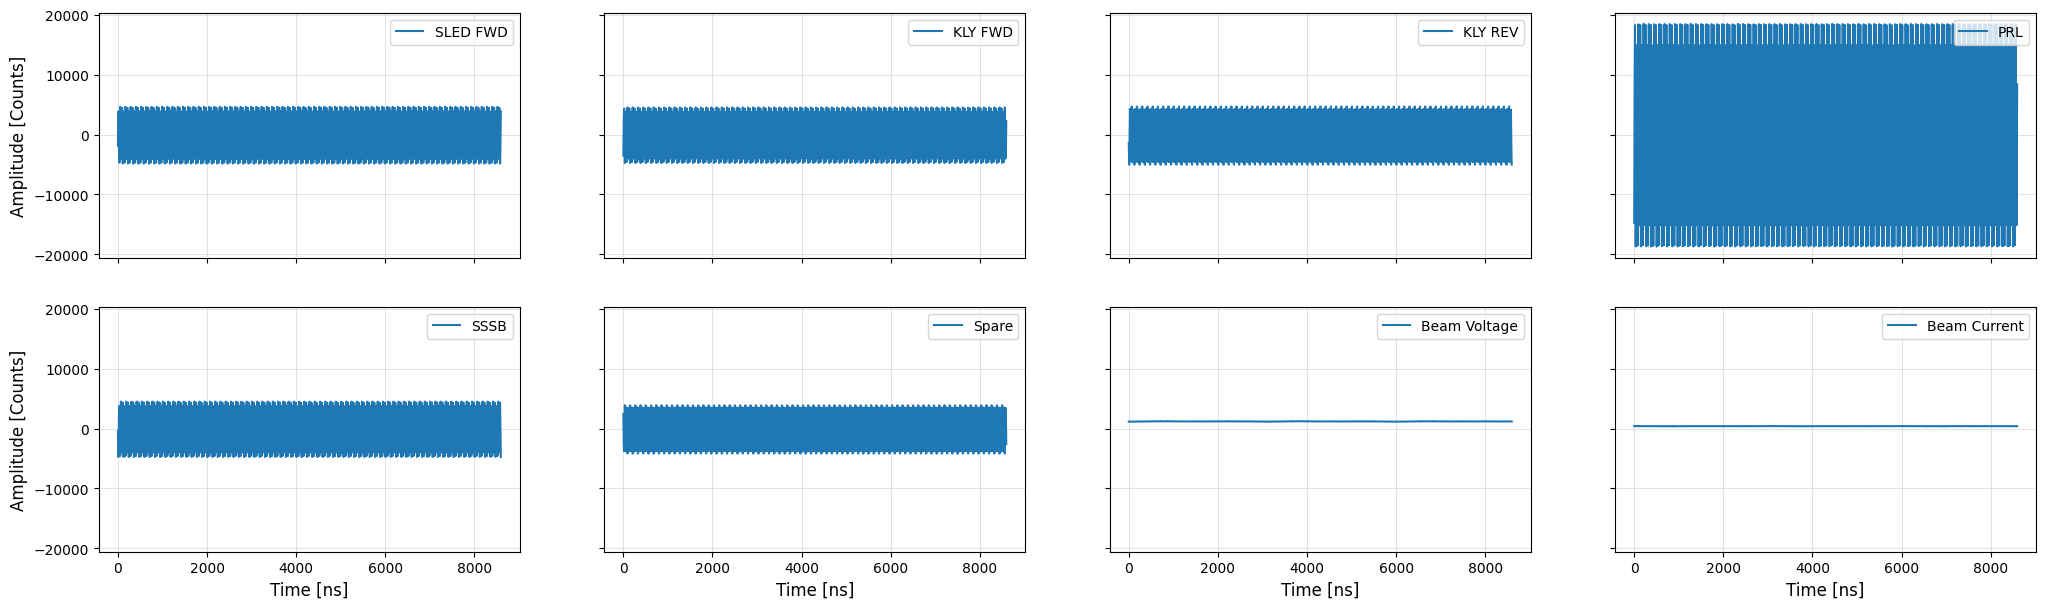

In [16]:
raw_wfms_df = llrf.get_raw_bufs_df()
plot_raw_bufs_df(raw_wfms_df)

In [17]:
raw_wfms_df.head()

,adc0,adc1,adc2,adc3,adc4,adc5,adc6,adc7
Time [ns],,,,,,,,
0.0,-1867,-3513,-1417,-14714,-484,2423,1165,411
8.4,3840,2261,-5034,8398,-4742,-2592,1155,416
16.8,3404,4343,-1100,18267,-1818,-3812,1146,410
25.2,-2501,-507,4264,-456,3741,670,1164,412
33.6,-4685,-4747,2722,-18680,3289,3884,1163,415


### Frequency Analysis

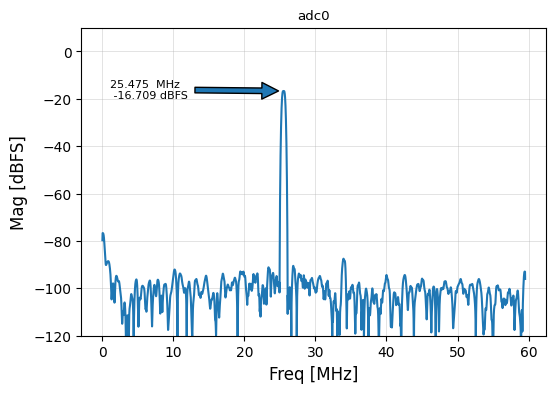

In [18]:
f, psd_dbfs = calc_ps(raw_wfms_df[fdbk_adc], fs_mhz=1e3/llrf.dsp_clk_ns)
plot_ps(f, psd_dbfs, title=fdbk_adc, annotate=True)

## Amplitude and Phase snapshot

Measure a snapshot of RF amplitude and phases after integrator conveyor belt in the `cic_wave_recorder`

In [19]:
df_mon = llrf.get_rfmon()
df_mon

,mon_amp,mon_phs,Amp [cnt],Phs [deg]
adc0,2852,10540,4784.901773,2.894897e+01
adc1,2788,1381,4677.526698,3.793030e+00
adc2,2898,-41783,4862.077608,-1.147604e+02
adc3,11292,9,18944.989769,2.471924e-02
adc4,2785,-45530,4672.493492,-1.250519e+02
adc5,2403,-61625,4031.598514,-1.692581e+02
adc6,1507,0,2528.347466,1.681949e-15
adc7,494,-1,828.801359,-2.746582e-03
drv0,6706,-32768,20004.665179,4.322983e-13
drv1,10057,-32768,30001.031569,4.322983e-13


Confirm MO phase is aligned

In [20]:
assert -0.2 < df_mon['Phs [deg]'][mo_adc] < 0.2

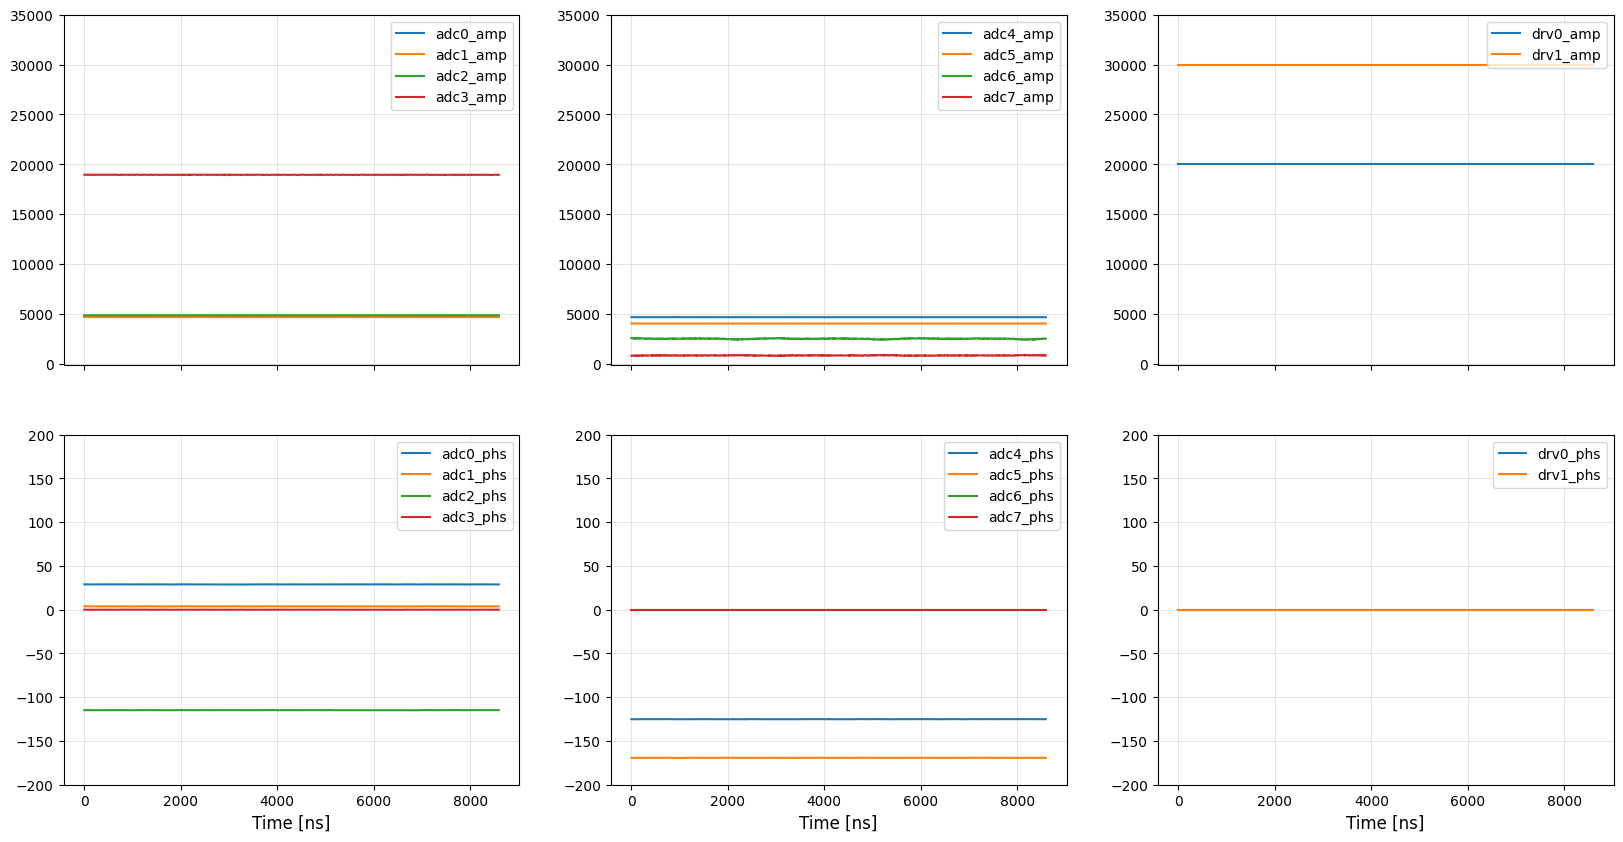

In [21]:
len_ns = 9000 
df_iq = llrf.get_iq_wfms_df() 
ylim_amp=(-100,35000)
plot_iq_wfms_df(df_iq, ylim_amp=ylim_amp, len_ns=len_ns)

# Pulse mode test with BV and BC

In [22]:
pl1 = 4  # us
pulse1_high_len = int(pl1 * 1000 / llrf.dsp_clk_ns)
pl2 = 5  # us
pulse2_high_len = int(pl2 * 1000 / llrf.dsp_clk_ns)

# Pulse mode and fiducial from timing
llrf.reg_write([
    ('loop0_pulse_high_len', pulse1_high_len),
    ('loop1_pulse_high_len', pulse2_high_len),
    ('drv0_pulse_mode', 1),
    ('drv1_pulse_mode', 1),
    ('wave_trig_sel',3),
    ('event_sel', 152)
])
time.sleep(0.5)

# Set delays to synch BV, BC and triggers
# 5us = (1/119MHz) * 595
# 6us = (1/119MHz) * 714
# 7us = (1/119MHz) * 833
llrf.reg_write([
    ('buf_delay', 595),
    ('loop0_pulse_start', 714),
    ('loop1_pulse_start', 833),
    ('trig_0_delay', 119),
    ('trig_1_delay', 357)
])
time.sleep(0.5)

print(f'pulse1_high_len: {pulse1_high_len} counts')
print(f'pulse2_high_len: {pulse2_high_len} counts')

pulse1_high_len: 476 counts
pulse2_high_len: 595 counts


In [23]:
# Enable Modulator trigger since it is the trigger for the signal generator to emulate BC and BV at b15
# 119 is 1us
llrf.reg_write([
    ('mod_permit', 1),
    ('trig_enables', 1),
    ('trig_0_width', 476),
    ('trig_0_delay', 595)
])

### RAW ADC & DAC data

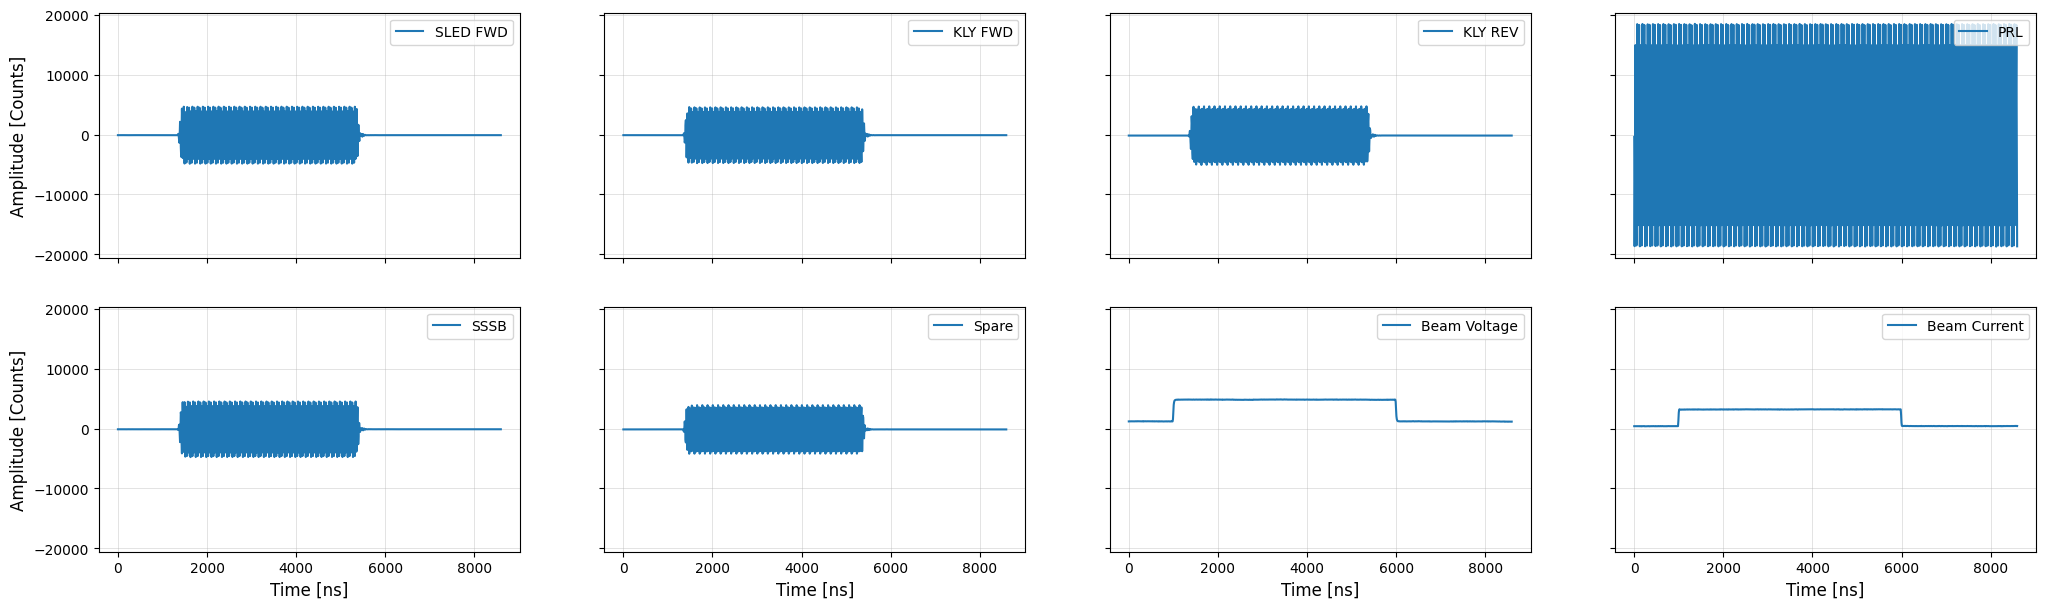

In [24]:
raw_wfms_df = llrf.get_raw_bufs_df()
plot_raw_bufs_df(raw_wfms_df)

### Slow data

In [25]:
from uspas_llrf.wave_collect import interpret_slow_data, wait_for_acq

tag_match, slow_data, time_now = wait_for_acq(llrf)
isd1 = interpret_slow_data(slow_data[17:])
print(f"ADC min: {isd1[5]}")
print(f"ADC max: {isd1[6]}")
print(f"Pulseid {isd1[7]}. Buffer counter {isd1[2]}. Ticks {isd1[8]}")

time.sleep(1)

tag_match, slow_data, time_now = wait_for_acq(llrf)
isd2 = interpret_slow_data(slow_data[17:])
print(f"ADC min: {isd2[5]}")
print(f"ADC max: {isd2[6]}")
print(f"Pulseid {isd2[7]}. Buffer counter {isd2[2]}. Ticks {isd2[8]}")

pulseID_freq = isd2[7] - isd1[7]
buffer_freq = isd2[2] - isd1[2]
print(f"PulseID freq: {pulseID_freq} Hz")
print(f"Buffer freq:  {buffer_freq} Hz")
assert abs(pulseID_freq - 360) <= 4, "PulseID is not at 360 Hz"
assert abs(buffer_freq - 120) <= 2, "Buffer counter is not at 120 Hz"

ADC min: [-4885, -4783, -5075, -20348, -4783, -4213, 1104, 334]
ADC max: [4647, 4578, 4706, 19443, 4517, 3904, 4875, 3234]
Pulseid 119142. Buffer counter 9415. Ticks 116129
ADC min: [-4885, -4779, -5074, -20406, -4783, -4214, 1108, 336]
ADC max: [4644, 4578, 4704, 19437, 4514, 3903, 4877, 3236]
Pulseid 119505. Buffer counter 9536. Ticks 116129
PulseID freq: 363 Hz
Buffer freq:  121 Hz


### High time-resolution I&Q Data

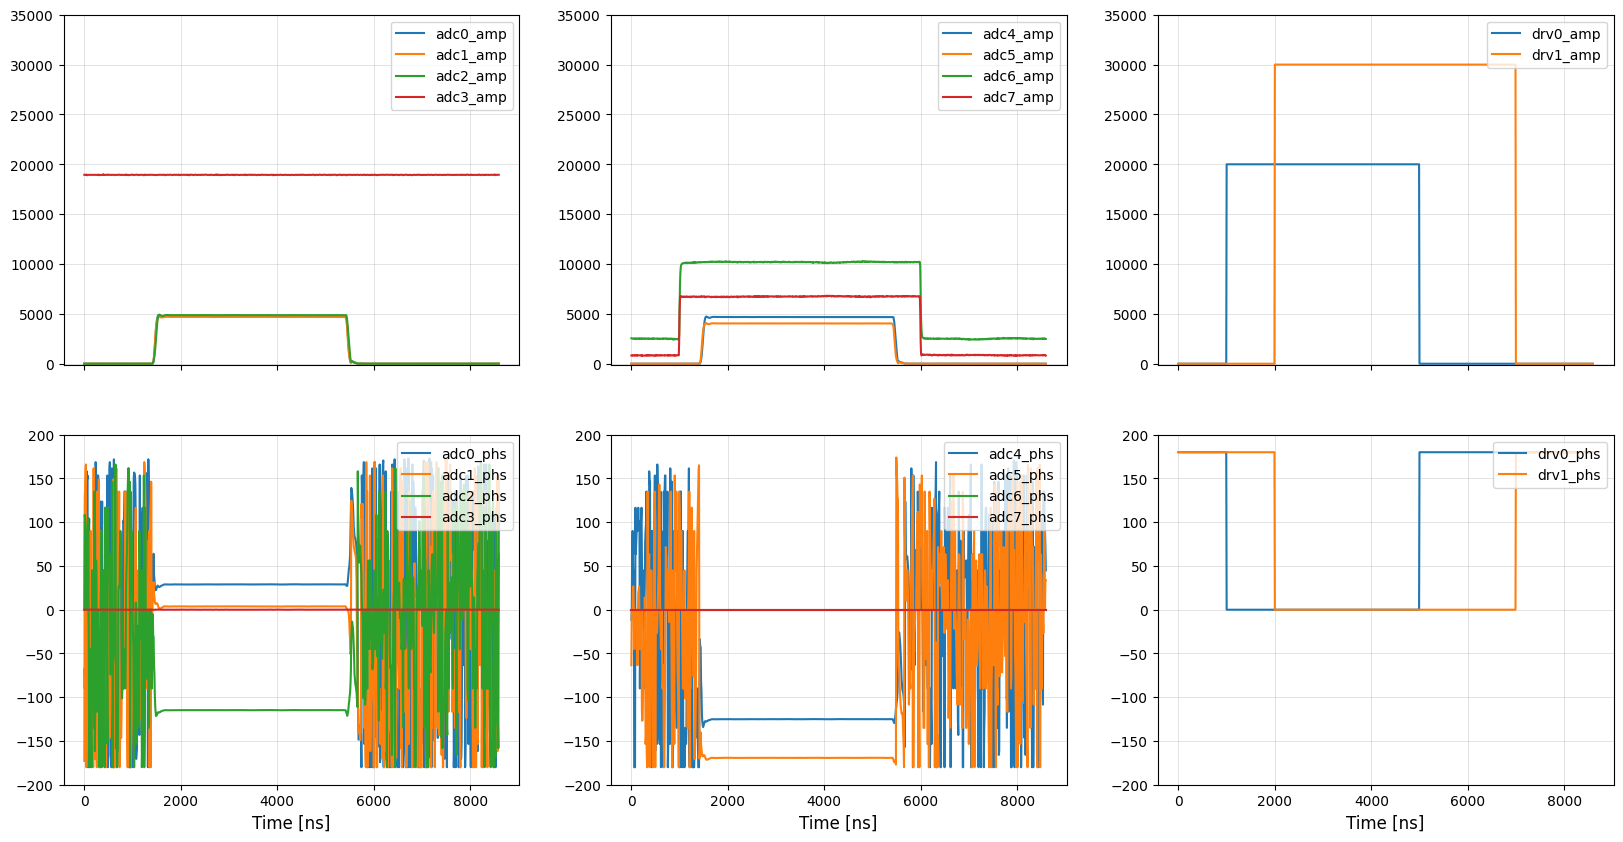

In [26]:
len_ns = 9000 
df_iq = llrf.get_iq_wfms_df() 
ylim_amp=(-100,35000)
plot_iq_wfms_df(df_iq, ylim_amp=ylim_amp, len_ns=len_ns)

Same, but from the iq_buf. Read of a single register that give all I&Q waveforms

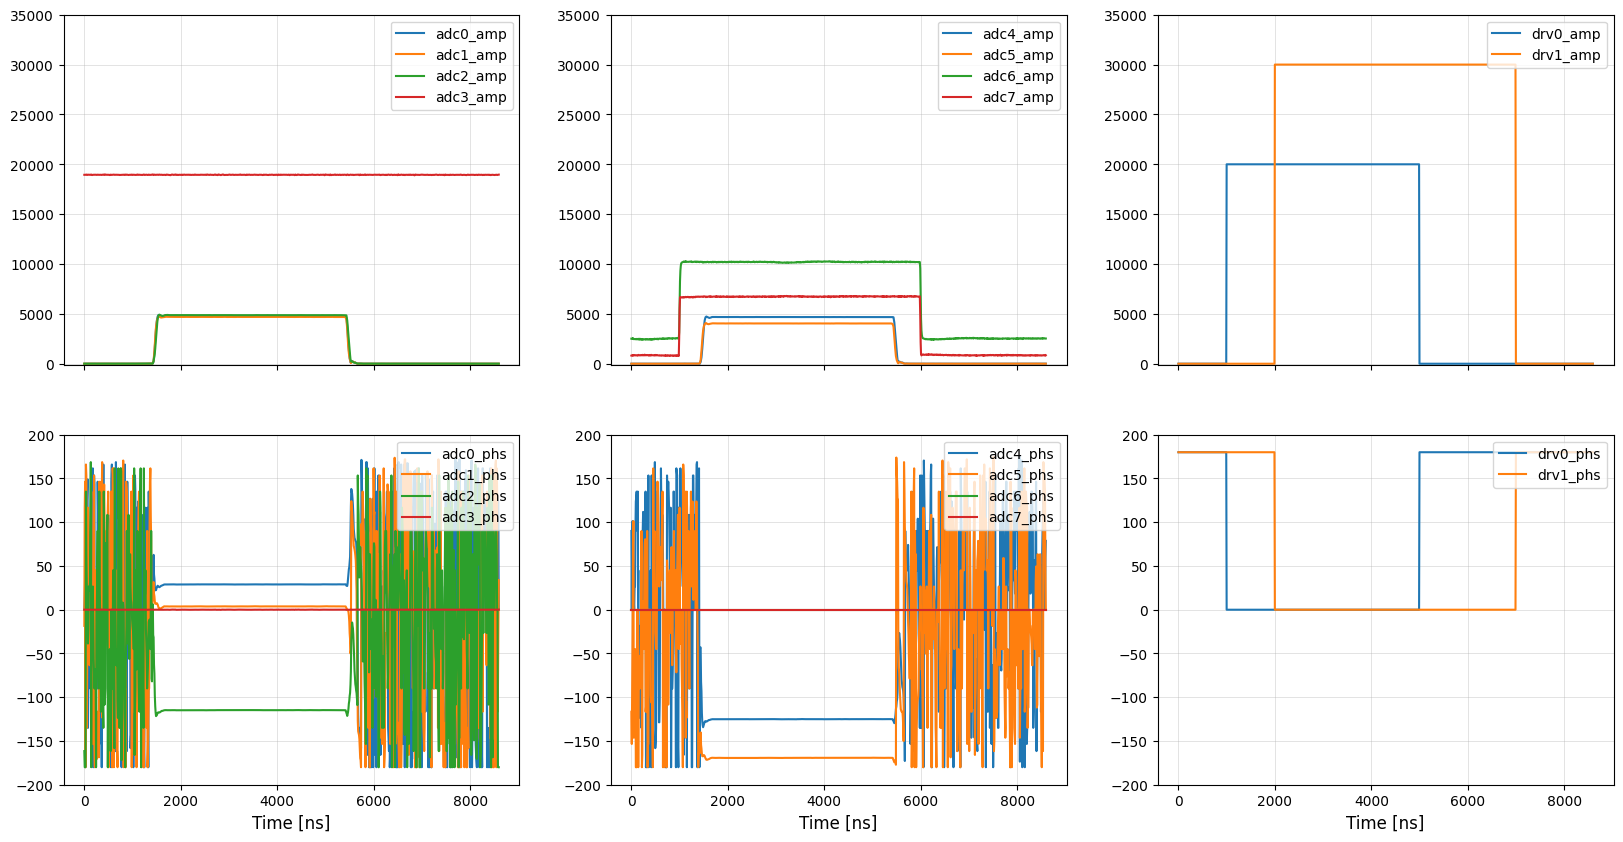

In [27]:
iq_buf = llrf.get_iq_wfms_df(single_buffer=True)
plot_iq_wfms_df(iq_buf, ylim_amp=ylim_amp, len_ns=len_ns)

In [28]:

amp = df_iq[[fdbk_adc + '_amp']].loc[2000:4000].values.mean()
phs = df_iq[[fdbk_adc + '_phs']].loc[2000:4000].values.mean()
print(f'fdbk_adc IQ waveform signal: amp = {amp:8.3f} cnt, phs = {phs:8.3f} deg')

amp_exp = df_mon['Amp [cnt]'][fdbk_adc]
phs_exp = df_mon['Phs [deg]'][fdbk_adc]
print(f'fdbk_adc expected inlk_mon:  amp = {amp_exp:8.3f} cnt, '
      f'phs = {phs_exp:8.3f} deg')

fdbk_adc IQ waveform signal: amp = 4799.569 cnt, phs =   28.923 deg
fdbk_adc expected inlk_mon:  amp = 4784.902 cnt, phs =   28.949 deg


### CIC buffer data

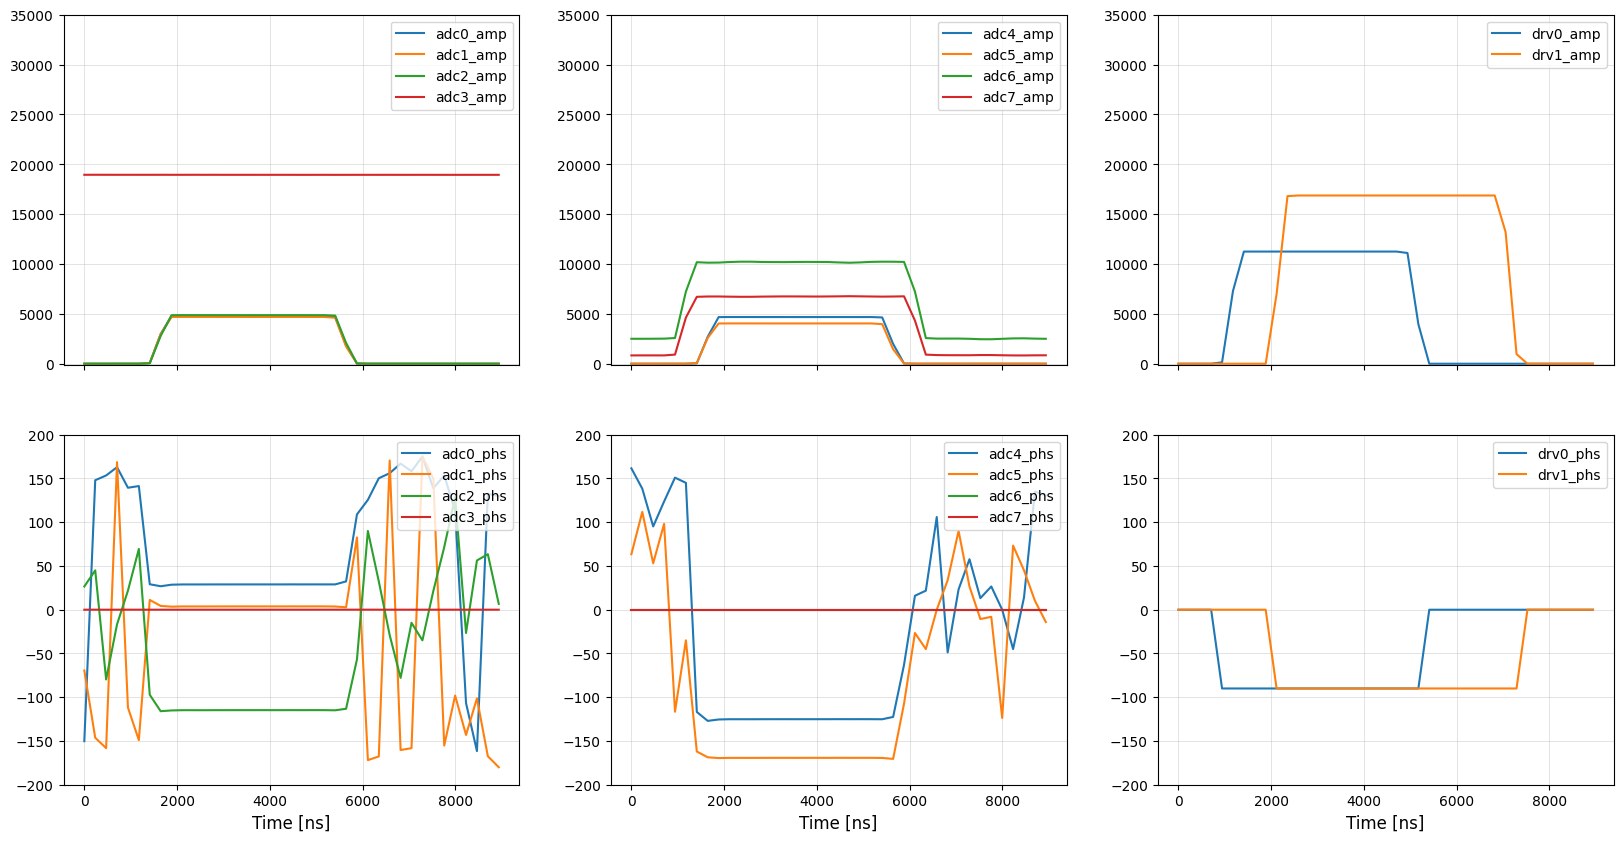

In [29]:
df_mp = llrf.get_cic_wfm_df()
ylim_amp=(-100,35000)
plot_iq_wfms_df(df_mp, ylim_amp=ylim_amp, len_ns=len_ns)

# Gain Analysis

## CIC Buffer

### Theory

In [30]:
from uspas_llrf.rx_gain import rx_theory_gain
import json
with open('../../uspas_llrf/settings.json', 'r') as file:
    settings = json.load(file)

cut = 4
num = settings['dsp_config']['LEMP']["NUM_DDS"]
den = settings['dsp_config']['LEMP']["DEN_DDS"]
wave_samp_per = llrf.read_reg('wave_samp_per')
cic_base_period = settings['dsp_config']['LEMP']["CIC_BASE_PERIOD"]
shift_base = settings['dsp_config']['LEMP']["CIC_SHIFT_BASE"]
amp = settings['dsp_config']['LEMP']["LO_AMP"]
rx = rx_theory_gain(cut, num, den, wave_samp_per,
                    cic_base_period, shift_base, amp,
                    verbose=True)
rx.washout_gain()
rx.ddc_gain()
rx.dds_gain()
rx.cic_gain()
total_g = rx.w_g * rx.ddc_g * rx.dds_g * rx.cic_g / 4
print('************** TOTAL GAIN **************')
print("Total gain:\t\t%.8f" % total_g)


Washout filter gain:	1.03141459
DDC gain:		1.94985582
DDS gain:		0.94027357
**********CIC gain calculation**********
shift_base:		7.00
wave_samp_per:		1.00
cic_base_period:	28.00
R:			28.00
bit growth:		9.61470984
SNR bit growth:		1.90367746
full shift:		7.00
wave shift:		0.00
exp:			4.61470984
CIC gain:		24.50000000
************** TOTAL GAIN **************
Total gain:		11.58233428


### RF

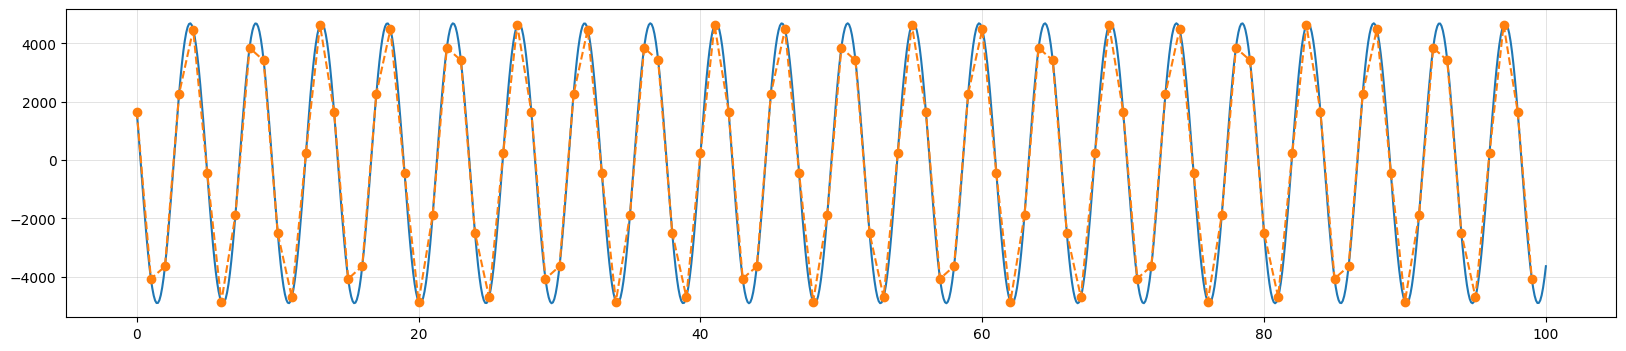

In [31]:
from uspas_llrf.utils import fit_sine

df_sig = llrf.get_raw_bufs_df()

fb_raw = df_sig[fdbk_adc].loc[:5000].to_numpy()
fb_raw_set = fb_raw[200:300]
x_fit, y_fit, A_fit = fit_sine(fb_raw_set, [30000,3/14,0,0])
plt.figure(figsize=(20, 4))
plt.plot(x_fit, y_fit)
plt.plot(fb_raw_set, '--o')

RF raw amplitude: 4801.100895124471
RF cic amplitude: 55584.42494759055
RF Measured gain gain: 11.577433209961628


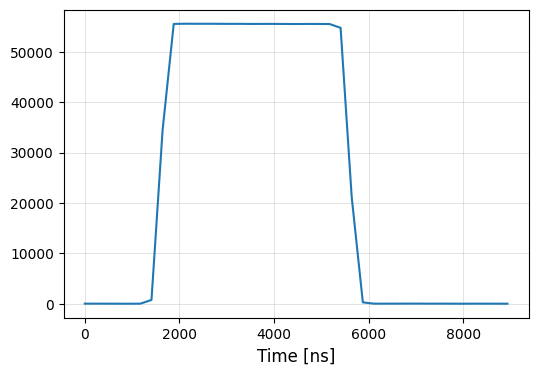

In [32]:
df_mp = llrf.get_cic_wfm_df() * abs(llrf.model.cic_wfm_gain)

raw_amp = abs(A_fit)
cic_amp = df_mp[fdbk_adc + '_amp'].loc[2200:4000].values.mean()
df_mp[fdbk_adc + '_amp'].loc[:9000].plot()

print("RF raw amplitude: %s" % raw_amp)
print("RF cic amplitude: %s" % cic_amp)
rx_total_gain = cic_amp / raw_amp
print("RF Measured gain gain: %s" % rx_total_gain)

In [33]:
ratio_g = rx_total_gain / total_g
print(ratio_g)
assert abs(ratio_g-1) <= 0.01, f"CIC RF gain theory and measured do not agree"

0.9995768491230675


### BV & BC

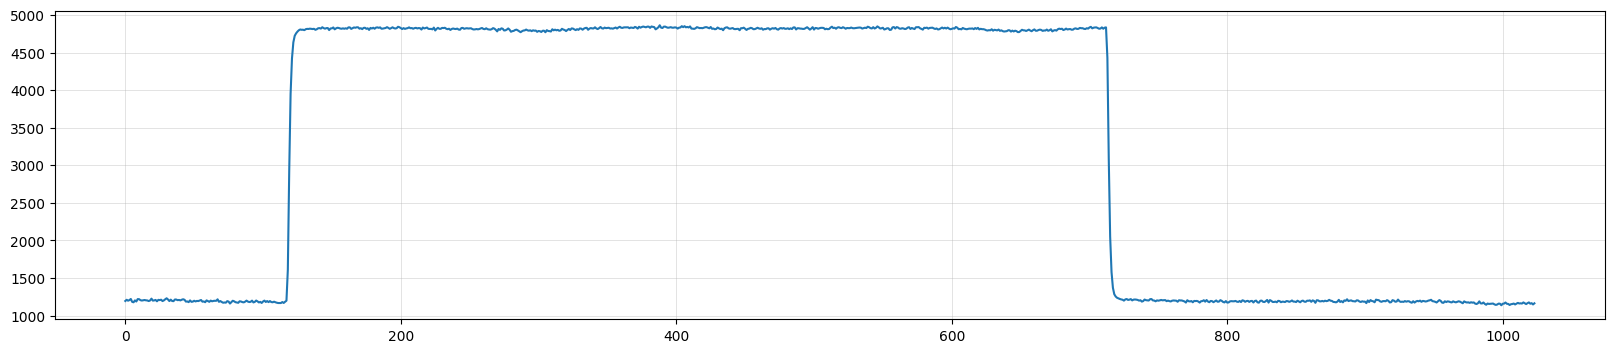

In [34]:
bv_raw = df_sig['adc6'].to_numpy()
bv_raw_amp = bv_raw[400:500].mean()
plt.figure(figsize=(20, 4))
plt.plot(bv_raw)


<Axes: xlabel='Time [ns]'>

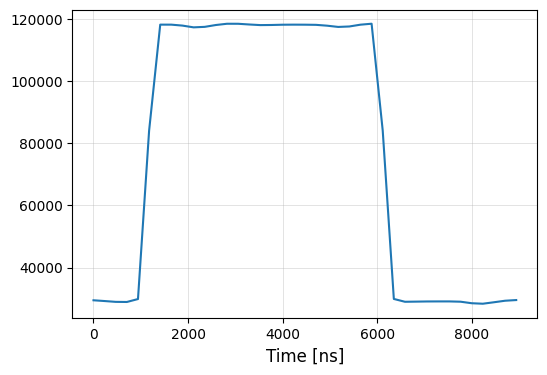

In [35]:
bv_cic_amp = df_mp['adc6' + '_amp'].loc[3000:4000].values.mean()
df_mp['adc6' + '_amp'].loc[:9000].plot()

In [36]:
print("BV & BC raw amplitude: %s" % bv_raw_amp)
print("BV & BC cic amplitude: %s" % bv_cic_amp)
bv_rx_total_gain = bv_cic_amp / bv_raw_amp
print("BV & BC Measured gain gain: %s" % bv_rx_total_gain)

BV & BC raw amplitude: 4822.38
BV & BC cic amplitude: 118217.0
BV & BC Measured gain gain: 24.514244003998026


The expected amplitude gain for BV and BC is the cic gain (24.5), since those signals do not go through any RF processing

In [37]:
ratio_bv_g = abs(bv_rx_total_gain / rx.cic_g)
assert abs(ratio_bv_g-1) <= 0.01, f"CIC BV&BC gain theory and measured do not agree"

## High time-resolution buffer gain analysis

### Theory

In [38]:
rx.washout_gain()
rx.ddc_gain()
rx.dds_gain()
total_hr_g = rx.w_g * rx.ddc_g * rx.dds_g
print('************** TOTAL GAIN **************')
print("Total gain:\t\t%.8f" % total_hr_g)

Washout filter gain:	1.03141459
DDC gain:		1.94985582
DDS gain:		0.94027357
************** TOTAL GAIN **************
Total gain:		1.89099335


### RF

RF raw amplitude: 4801.100895124471
RF I&Q amplitude: 9073.993344239247
RF Measured gain gain: 1.8899818067672578


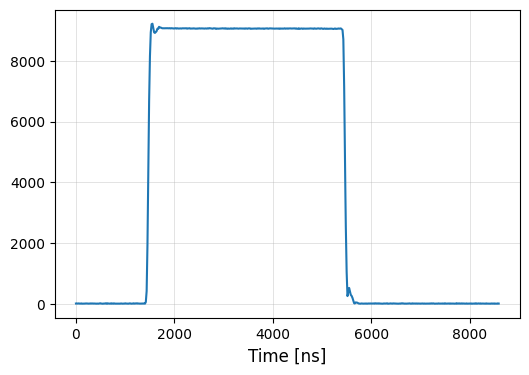

In [39]:
# Multiply by llrf.model.rx_iq_gain so gain is not applied when reading the data

df_iq = llrf.get_iq_wfms_df() * abs(llrf.model.rx_iq_gain)
hr_iq_amp = df_iq[fdbk_adc + '_amp'].loc[2000:3000].values.real.mean()
df_iq[fdbk_adc + '_amp'].loc[:9000].plot()

print("RF raw amplitude: %s" % raw_amp)
print("RF I&Q amplitude: %s" % hr_iq_amp)
hr_total_gain = hr_iq_amp / raw_amp
print("RF Measured gain gain: %s" % hr_total_gain)

In [40]:
ratio_hr_g = hr_total_gain / total_hr_g
assert abs(ratio_hr_g-1) <= 0.01, f"High-time resolution RF gain theory and measured do not agree"

### BV & BC

BV & BC raw amplitude: 4822.38
BV & BC amplitude: 19266.252100840335
BV & BC Measured gain gain: 3.995175017489359


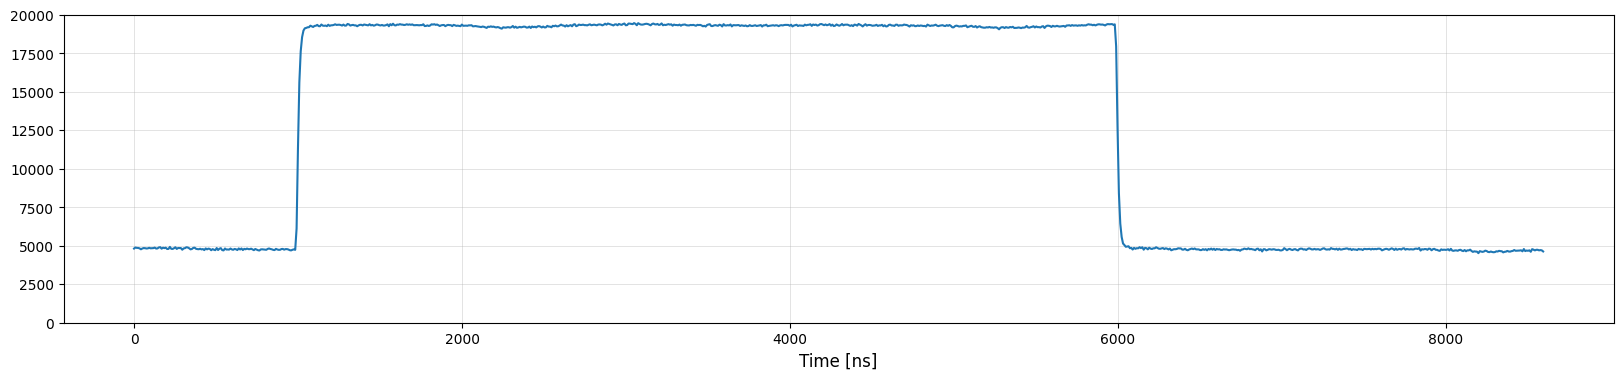

In [41]:
df_iq = llrf.get_iq_wfms_df() * abs(llrf.model.rx_iq_gain)
bv_hr_iq_amp = df_iq['adc6' + '_amp'].loc[2000:3000].values.real.mean()
df_iq['adc6' + '_amp'].loc[:9000].plot(figsize=(20, 4),ylim=(0, 20000))

print("BV & BC raw amplitude: %s" % bv_raw_amp)
print("BV & BC amplitude: %s" % bv_hr_iq_amp)
bv_hr_total_gain = bv_hr_iq_amp / bv_raw_amp
print("BV & BC Measured gain gain: %s" % bv_hr_total_gain)

The expected amplitude gain for BV and BC is 4, since there is no RF procesing for those signals, only a 2 bit shift.

In [42]:
ratio_bv_hr_g = abs(bv_hr_total_gain / 4.0)
assert abs(ratio_bv_hr_g-1) <= 0.05, f"High-time resolution BV&BC gain theory and measured do not agree"

# Theory Appendix

\begin{array}{|c|c|c|}
\hline
                            & \text{RF Gain} & \text{BV\&BC Gain} \\ \hline
\text{CIC Buffer}           & 11.58233428    & 24.5 \\ \hline
\text{High time-res buffer} & 1.89099335     & 4 \\ \hline
\end{array}

Gain from raw ADC data to circular buffer is:

$G = G_{wf} * G_{ddc} * G_{dds} * G_{cic} * C$

### Washout filter

$G_{wf}=\frac{z-1}{z(z-p)}$

where $z=e^{j2\pi \frac{num}{den}}$, $p = \frac{N-1}{N}$ and $N=2^{cut}$

### Non-iq Digital Downconverter (DDC)

$G_{ddc} = 2 * \sin{(2 \pi \frac{num}{den})}$

### Direct Digital Synthesizer (DDS)

$G_{dds} = G_{cordic} * \frac{amp}{2^{width}}$

### CIC Wave Recorder

$G_{cic} = 2^{bg - sb + 2 - (2*ws)}$

where

$ws = ceil(max((fs-sb)/2,0))$

$fs = floor(bg - snr)$

$snr = \frac{\log_{2}{R/2}}{2}$

$bg = 2 * \log_{2}{R}$

$R = wsp * bp$


# Interlock Check
This section helps to check the functional interlocks (KLY REV, BV, BC). The other interlocks are not functional and bypass at the moment

The modulator status is not checked here

In [43]:
# Set interlock thresholds
llrf.reg_write([
    ('beam_vol_thr', 10000),
    ('beam_cur_thr', 20000),
    ('kr_amp_thr', 20000)
])
time.sleep(1.0)
# Bypass unused interlocks
#   bit 0:  Internal PLL lock fault               BYPASS
#   bit 1:  EPICS timeout                         BYPASS
#   bit 2:  Local oscillator out-of-range fault   BYPASS
#   bit 3:  Klystron reverse amplitude
#   bit 4:  Beam over-voltage
#   bit 5:  Beam over-current
#   bit 6:  Admin timeout (NOT YET USED)          BYPASS
#   bit 7:  Modulator status fault
llrf.reg_write([('intlk_intlk_byp', 0x47)])
time.sleep(1.0)

# Reset interlocks
llrf.reg_write([('intlk_intlk_reset', 0x1ff)])

#### KLY REV interlock

In [44]:
print(f'KLY REV max:\t{llrf.reg_read(["kr_amp_max"])[0]}')
intlk_latch = llrf.reg_read(['intlk_latch'])[0]
print(f'Intelock latch:\t{bin(intlk_latch)}')
llrf.init_loop('loop0', amp_setp_adc=3e4)
time.sleep(1)
print(f'KLY REV max:\t{llrf.reg_read(["kr_amp_max"])[0]}')
intlk_latch = llrf.reg_read(['intlk_latch'])[0]
print(f'Intelock latch:\t{bin(intlk_latch)}')
assert intlk_latch != 0, 'Interlock latch is not set'
time.sleep(1)
llrf.init_loop('loop0', amp_setp_adc=2e4)
llrf.reg_write([('intlk_intlk_reset', 0x1ff)])
llrf.reg_write([('kr_amp_max_rst', 0x1)])
time.sleep(1)
print(f'KLY REV max:\t{llrf.reg_read(["kr_amp_max"])[0]}')
intlk_latch = llrf.reg_read(['intlk_latch'])[0]
print(f'Intelock latch:\t{bin(intlk_latch)}')
assert intlk_latch == 0, 'Interlock latch is set. Interlock reset failed'


KLY REV max:	16074
Intelock latch:	0b0
KLY REV max:	22987
Intelock latch:	0b1000
KLY REV max:	15362
Intelock latch:	0b0


#### BV & BC

In [45]:
for i in ['vol', 'cur']:
    print(f'\nTesting beam {i}')
    llrf.reg_write([(f'beam_{i}_max_rst', 0x1)])
    time.sleep(1)
    print(f'Beam {i} max:\t{llrf.reg_read([f"beam_{i}_max"])[0]}')
    print(f'Intelock latch:\t{bin(llrf.reg_read(["intlk_latch"])[0])}')
    time.sleep(1)
    llrf.reg_write([(f'beam_{i}_thr', 1000)])
    time.sleep(1)
    print(f'Beam {i} max:\t{llrf.reg_read([f"beam_{i}_max"])[0]}')
    intlk_latch = llrf.reg_read(["intlk_latch"])[0]
    print(f'Intelock latch:\t{bin(intlk_latch)}')
    assert intlk_latch != 0, 'Interlock latch is not set'
    time.sleep(1)
    llrf.reg_write([(f'beam_{i}_thr', 10000)])
    llrf.reg_write([('intlk_intlk_reset', 0x1ff)])
    llrf.reg_write([(f'beam_{i}_max_rst', 0x1)])
    time.sleep(1)
    print(f'Beam {i} max:\t{llrf.reg_read([f"beam_{i}_max"])[0]}')
    intlk_latch = llrf.reg_read(["intlk_latch"])[0]
    print(f'Intelock latch:\t{bin(intlk_latch)}')
    assert intlk_latch == 0, 'Interlock latch is set. Interlock reset failed'



Testing beam vol
Beam vol max:	4877
Intelock latch:	0b0
Beam vol max:	4877
Intelock latch:	0b10000
Beam vol max:	4876
Intelock latch:	0b0

Testing beam cur
Beam cur max:	3237
Intelock latch:	0b0
Beam cur max:	3244
Intelock latch:	0b100000
Beam cur max:	3232
Intelock latch:	0b0


# Triggers Check
Below the triggers are configured, and need to be checked with an oscilloscope

In [46]:
# triggers: modulator, SSSB, scope, spare
# 119 is 1us
llrf.reg_write([
    ('trig_enables', 0b0111),
    ('trig_0_width', 119),
    ('trig_0_delay', 595),
    ('trig_1_width', 10000),
    ('trig_1_delay', 700),
    ('trig_2_width', 10000),
    ('trig_2_delay', 595),
    ('trig_3_width', 476),
    ('trig_3_delay', 595)
])